In [0]:
%sql
CREATE VOLUME IF NOT EXISTS workspace.default.water_assessment

In [0]:
BASE_PATH = "/Volumes/workspace/default/water_assessment"
display(dbutils.fs.ls(BASE_PATH))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/water_assessment/water_meter_readings.csv,water_meter_readings.csv,11125,1794400905000
dbfs:/Volumes/workspace/default/water_assessment/water_reading_changes.csv,water_reading_changes.csv,956,1794400905000
dbfs:/Volumes/workspace/default/water_assessment/water_readings_incremental.csv,water_readings_incremental.csv,1391,1794400905000
dbfs:/Volumes/workspace/default/water_assessment/water_service_requests.csv,water_service_requests.csv,2662,1794400905000
dbfs:/Volumes/workspace/default/water_assessment/water_zones.json,water_zones.json,2343,1794400905000


In [0]:
import re
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, StringType, DoubleType, TimestampType
)
dbutils.widgets.text("catalog", "workspace")
dbutils.widgets.text("schema", "default")
dbutils.widgets.text("volume", "water_assessment")
catalog = dbutils.widgets.get("catalog").strip()
schema = dbutils.widgets.get("schema").strip()
volume = dbutils.widgets.get("volume").strip()
for label, value in [("catalog", catalog), ("schema", schema), ("volume", volume)]:
    if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", value):
        raise ValueError(f"Invalid {label}: use letters, digits and underscores only")
namespace = f"`{catalog}`.`{schema}`"
base_path = f"/Volumes/{catalog}/{schema}/{volume}"
print("Data location:", base_path)
required = [
    "water_meter_readings.csv", "water_zones.json", "water_service_requests.csv",
    "water_reading_changes.csv", "water_readings_incremental.csv"
]
try:
    available = {entry.name.rstrip("/") for entry in dbutils.fs.ls(base_path)}
except Exception as exc:
    raise RuntimeError(f"Cannot access {base_path}. Create the Volume and upload the files first.") from exc
missing = sorted(set(required) - available)
if missing:
    raise FileNotFoundError(f"Missing data files in {base_path}: {missing}")
spark.sql(f"USE CATALOG `{catalog}`")
spark.sql(f"USE SCHEMA `{schema}`")
def save_delta(df, name):
    (df.write.format("delta")
       .mode("overwrite")
       .option("overwriteSchema", "true")
       .saveAsTable(f"{catalog}.{schema}.{name}"))

Data location: /Volumes/workspace/default/water_assessment


In [0]:
reading_schema = StructType([
    StructField("reading_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reading_time", TimestampType(), True),
    StructField("flow_lpm", DoubleType(), True),
    StructField("pressure_bar", DoubleType(), True),
    StructField("chlorine_mg_l", DoubleType(), True),
    StructField("consumption_liters", IntegerType(), True),
    StructField("reading_status", StringType(), True),
    StructField("source_system", StringType(), True),
])
def read_readings(filename):
    return (spark.read.format("csv")
        .option("header", "true")
        .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
        .schema(reading_schema)
        .load(f"{base_path}/{filename}"))
source = read_readings("water_meter_readings.csv")
save_delta(source, "water_meter_readings_source")
save_delta(source, "water_meter_readings_work")
save_delta(read_readings("water_reading_changes.csv"), "water_reading_changes")
save_delta(read_readings("water_readings_incremental.csv"), "water_readings_incremental_staging")

In [0]:
zone_raw = spark.read.json(f"{base_path}/water_zones.json")
save_delta(zone_raw, "water_zones_raw")
zone_flat = zone_raw.select(
    "zone_id", "zone_name",
    F.col("location.city").alias("city"),
    F.col("location.district").alias("district"),
    "zone_type", "daily_capacity_liters", "active", "commissioned_on"
)
save_delta(zone_flat, "water_zones")

In [0]:
request_schema = StructType([
    StructField("request_id", IntegerType(), True),
    StructField("meter_id", StringType(), True),
    StructField("zone_id", StringType(), True),
    StructField("reported_at", TimestampType(), True),
    StructField("issue_type", StringType(), True),
    StructField("priority", StringType(), True),
    StructField("estimated_cost", DoubleType(), True),
    StructField("work_status", StringType(), True),
])
requests = (spark.read.option("header", "true")
    .option("timestampFormat", "yyyy-MM-dd HH:mm:ss")
    .schema(request_schema)
    .csv(f"{base_path}/water_service_requests.csv"))
save_delta(requests, "water_service_requests")

In [0]:
for name in [
    "water_meter_readings_source", "water_meter_readings_work",
    "water_zones_raw", "water_zones", "water_service_requests",
    "water_reading_changes", "water_readings_incremental_staging"
]:
    print(f"{catalog}.{schema}.{name}: {spark.table(f'{catalog}.{schema}.{name}').count()} rows")
print("SETUP COMPLETE. Do not rerun after beginning exercises or pipeline ingestion.")

workspace.default.water_meter_readings_source: 157 rows
workspace.default.water_meter_readings_work: 157 rows
workspace.default.water_zones_raw: 11 rows
workspace.default.water_zones: 11 rows
workspace.default.water_service_requests: 36 rows
workspace.default.water_reading_changes: 12 rows
workspace.default.water_readings_incremental_staging: 18 rows
SETUP COMPLETE. Do not rerun after beginning exercises or pipeline ingestion.


In [0]:
from delta.tables import DeltaTable

##Section A | SQL Querying and Filtering

01. Inspect water_meter_readings_source and display its schema and total row count.

In [0]:
%sql
DESCRIBE TABLE water_meter_readings_source

col_name,data_type,comment
reading_id,int,null
meter_id,string,null
zone_id,string,null
reading_time,timestamp,null
flow_lpm,double,null
pressure_bar,double,null
chlorine_mg_l,double,null
consumption_liters,int,null
reading_status,string,null
source_system,string,null


In [0]:
%sql
SELECT COUNT(*) AS total_rows FROM water_meter_readings_source

total_rows
157


02. Retrieve reading_id, meter_id, zone_id, reading_time and consumption_liters for readings marked Valid.

In [0]:
%sql
SELECT reading_id, meter_id, zone_id, reading_time, consumption_liters
FROM water_meter_readings_source WHERE reading_status = 'Valid'

reading_id,meter_id,zone_id,reading_time,consumption_liters
1001,M001,W01,2026-10-01T07:00:00.000Z,2365
1002,M002,W02,2026-10-01T08:10:00.000Z,3545
1003,M003,W03,2026-10-01T09:20:00.000Z,548
1004,M004,W04,2026-10-01T10:00:00.000Z,2871
1006,M006,W06,2026-10-01T12:20:00.000Z,2171
1007,M007,W07,2026-10-01T13:00:00.000Z,4167
1008,M008,W08,2026-10-01T14:10:00.000Z,3621
1009,M009,W09,2026-10-01T15:20:00.000Z,1609
1010,M010,W10,2026-10-01T16:00:00.000Z,1829
1011,M011,W01,2026-10-02T07:10:00.000Z,313


03. Find readings where pressure_bar is below 2.5, ordering the results from lowest pressure upward.

In [0]:
%sql
SELECT * FROM water_meter_readings_source
WHERE pressure_bar < 2.5 ORDER BY pressure_bar ASC

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1071,M011,W01,2026-10-08T07:10:00.000Z,10.9,1.8,0.8,647,Valid,SmartMeter
1064,M004,W04,2026-10-07T10:00:00.000Z,20.3,1.82,0.84,708,Valid,Gateway
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1116,M026,W06,2026-10-12T12:10:00.000Z,28.9,1.84,0.36,1692,Valid,SmartMeter
1133,M013,W03,2026-10-14T09:00:00.000Z,15.6,1.86,0.8,900,Valid,Gateway
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1051,M021,W01,2026-10-06T07:20:00.000Z,72.0,1.93,0.27,1818,Valid,FieldApp
1052,M022,W02,2026-10-06T08:00:00.000Z,74.0,1.94,0.21,4669,Valid,Gateway
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter


04. Find records where flow_lpm is between 20 and 50 and the source_system is Gateway or SmartMeter.

In [0]:
%sql
SELECT * FROM water_meter_readings_source
WHERE flow_lpm BETWEEN 20 AND 50 AND source_system IN ('Gateway', 'SmartMeter')

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1001,M001,W01,2026-10-01T07:00:00.000Z,39.1,3.56,0.75,2365,Valid,Gateway
1014,M014,W04,2026-10-02T10:10:00.000Z,22.4,4.73,0.5,1108,Valid,SmartMeter
1017,M017,W07,2026-10-02T13:10:00.000Z,28.0,3.77,1.08,1318,Valid,SmartMeter
1019,M019,W09,2026-10-02T15:00:00.000Z,23.0,4.34,0.28,1091,Valid,Gateway
1022,M022,W02,2026-10-03T08:00:00.000Z,32.5,3.35,0.6,1706,Suspect,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1047,M017,W07,2026-10-05T13:10:00.000Z,28.8,3.23,0.91,1258,Valid,SmartMeter
1049,M019,W09,2026-10-05T15:00:00.000Z,21.4,2.43,0.47,611,Valid,Gateway
1050,M020,W10,2026-10-05T16:10:00.000Z,37.2,3.91,1.02,2154,Valid,SmartMeter
1056,M026,W06,2026-10-06T12:10:00.000Z,27.2,2.69,0.68,1131,Suspect,SmartMeter


05. List distinct reading_status values and count how many readings belong to each status.

In [0]:
%sql
SELECT reading_status, COUNT(*) AS reading_count
FROM water_meter_readings_source GROUP BY reading_status ORDER BY reading_count DESC

reading_status,reading_count
Valid,137
Suspect,11
Rejected,9


##Section B | Joins, Aggregations and Window Functions

06. Join meter readings with water_zones and show zone_name, district, meter_id and consumption_liters.

In [0]:
%sql
SELECT z.zone_name, z.district, r.meter_id, r.consumption_liters
FROM water_meter_readings_source r
JOIN water_zones z ON r.zone_id = z.zone_id

zone_name,district,meter_id,consumption_liters
Old City,Central,M001,2365
Hill View,North,M002,3545
Market District,Central,M003,548
Lake Side,West,M004,2871
University Quarter,East,M005,2656
Industrial Estate,South,M006,2171
Garden Colony,North,M007,4167
Transit Hub,East,M008,3621
Riverfront,West,M009,1609
South Extension,South,M010,1829


07. Find reading records whose zone_id has no matching entry in water_zones.

In [0]:
%sql
SELECT r.* FROM water_meter_readings_source r
LEFT JOIN water_zones z ON r.zone_id = z.zone_id WHERE z.zone_id IS NULL

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1154,M999,W99,2026-10-16T11:00:00.000Z,24.5,3.0,0.45,1150,Valid,FieldApp
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


08. Find zones that currently have no meter readings, using a suitable join.

In [0]:
%sql
SELECT z.zone_id, z.zone_name FROM water_zones z
LEFT JOIN water_meter_readings_source r ON z.zone_id = r.zone_id
WHERE r.reading_id IS NULL

zone_id,zone_name
W11,New Development


09. Calculate total valid consumption, average pressure and reading count for each zone; exclude
nonpositive consumption.

In [0]:
%sql
SELECT zone_id,SUM(consumption_liters) AS total_consumption,
ROUND(AVG(pressure_bar), 2) AS avg_pressure,COUNT(*) AS reading_count
FROM water_meter_readings_source WHERE reading_status = 'Valid' AND consumption_liters > 0
GROUP BY zone_id ORDER BY total_consumption DESC

zone_id,total_consumption,avg_pressure,reading_count
W03,35665,3.02,13
W08,33689,2.87,14
W05,28717,3.63,14
W10,27808,3.72,14
W07,25104,3.57,13
W02,24120,3.31,13
W01,23107,3.42,13
W09,20894,3.55,13
W04,20781,3.24,14
W06,20212,3.16,13


10. Rank meters by total valid consumption within each district using a SQL window function.

In [0]:
%sql
WITH meter_totals AS (
  SELECT z.district, r.meter_id, SUM(r.consumption_liters) AS total_consumption FROM water_meter_readings_source r
  JOIN water_zones z ON r.zone_id = z.zone_id
  WHERE r.reading_status = 'Valid' AND r.consumption_liters > 0
  GROUP BY z.district, r.meter_id
)
SELECT district, meter_id, total_consumption,RANK() OVER (PARTITION BY district ORDER BY total_consumption DESC) AS rank_in_district
FROM meter_totals ORDER BY district, rank_in_district

district,meter_id,total_consumption,rank_in_district
Central,M023,17814,1
Central,M001,11416,2
Central,M003,10447,3
Central,M013,7404,4
Central,M021,7395,5
Central,M011,4296,6
East,M008,14095,1
East,M018,10660,2
East,M025,10536,3
East,M015,9807,4


##Section C | PySpark DataFrame Operations

11. Load the meter readings and zone master Delta tables into separate PySpark DataFrames; print their
schemas.

In [0]:
readings = spark.table("water_meter_readings_source")
zones = spark.table("water_zones")

readings.printSchema()
zones.printSchema()

root
 |-- reading_id: integer (nullable = true)
 |-- meter_id: string (nullable = true)
 |-- zone_id: string (nullable = true)
 |-- reading_time: timestamp (nullable = true)
 |-- flow_lpm: double (nullable = true)
 |-- pressure_bar: double (nullable = true)
 |-- chlorine_mg_l: double (nullable = true)
 |-- consumption_liters: integer (nullable = true)
 |-- reading_status: string (nullable = true)
 |-- source_system: string (nullable = true)

root
 |-- zone_id: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- district: string (nullable = true)
 |-- zone_type: string (nullable = true)
 |-- daily_capacity_liters: long (nullable = true)
 |-- active: boolean (nullable = true)
 |-- commissioned_on: string (nullable = true)



12. Use select(), filter() and orderBy() to display high-flow Valid readings.

In [0]:
high_flow = (readings.select("reading_id", "meter_id", "zone_id", "flow_lpm", "pressure_bar").filter((F.col("reading_status") == "Valid") & (F.col("flow_lpm") >= 60)).orderBy(F.col("flow_lpm").desc()))
display(high_flow)

reading_id,meter_id,zone_id,flow_lpm,pressure_bar
1110,M020,W10,84.0,4.45
1106,M016,W06,83.9,4.69
1083,M023,W03,83.9,2.68
1010,M010,W10,81.3,2.38
1013,M013,W03,80.7,3.8
1078,M018,W08,80.7,2.28
1093,M003,W03,80.4,4.35
1031,M001,W01,80.1,2.38
1123,M003,W03,79.7,2.11
1044,M014,W04,79.3,1.95


13. Add a flow_category column: High for flow_lpm >= 60, Medium for 30 to below 60, Low otherwise;
handle nulls explicitly.

In [0]:
readings_cat = readings.withColumn(
    "flow_category",
    F.when(F.col("flow_lpm").isNull(), "Unknown")
     .when(F.col("flow_lpm") >= 60, "High")
     .when(F.col("flow_lpm") >= 30, "Medium")
     .otherwise("Low")
)
display(readings_cat.select("reading_id", "flow_lpm", "flow_category"))

reading_id,flow_lpm,flow_category
1001,39.1,Medium
1002,59.9,Medium
1003,25.7,Low
1004,56.7,Medium
1005,61.8,High
1006,35.8,Medium
1007,65.0,High
1008,70.3,High
1009,30.8,Medium
1010,81.3,High


14. Join the DataFrames and calculate average flow_lpm for each zone_type.

In [0]:
avg_flow = (readings.join(zones, "zone_id").groupBy("zone_type").agg(F.round(F.avg("flow_lpm"), 2).alias("avg_flow_lpm")))
display(avg_flow)

zone_type,avg_flow_lpm
Commercial,56.1
Residential,45.16
Mixed,38.17
Industrial,43.14
Institutional,49.33


15. Use PySpark groupBy() and agg() to identify the three zones with the highest valid water consumption.

In [0]:
valid = readings.filter((F.col("reading_status") == "Valid") & (F.col("consumption_liters") > 0))
top3 = (valid.groupBy("zone_id").agg(F.sum("consumption_liters").alias("total_consumption")).orderBy(F.col("total_consumption").desc()).limit(3))
display(top3)

zone_id,total_consumption
W03,35665
W08,33689
W05,28717


##Section D | Data Quality and Cleaning

16. Identify duplicate reading_id values and display every row associated with those IDs.

In [0]:
%sql
SELECT *
FROM water_meter_readings_source
WHERE reading_id IN (
  SELECT reading_id FROM water_meter_readings_source GROUP BY reading_id
  HAVING COUNT(*) > 1
) ORDER BY reading_id

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1044,M014,W04,2026-10-05T10:10:00.000Z,79.3,1.95,1.23,2661,Valid,SmartMeter
1044,M014,W04,2026-10-16T13:00:00.000Z,36.0,3.2,0.8,1300,Valid,Gateway


17. Find missing pressure_bar and source_system values and count the affected records.

In [0]:
%sql
SELECT
  SUM(CASE WHEN pressure_bar IS NULL THEN 1 ELSE 0 END) AS missing_pressure,
  SUM(CASE WHEN source_system IS NULL THEN 1 ELSE 0 END) AS missing_source_system,
  SUM(CASE WHEN pressure_bar IS NULL OR source_system IS NULL THEN 1 ELSE 0 END) AS rows_affected
FROM water_meter_readings_source

missing_pressure,missing_source_system,rows_affected
1,1,2


In [0]:
%sql
SELECT * FROM water_meter_readings_source WHERE pressure_bar IS NULL OR source_system IS NULL

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1153,M020,W10,2026-10-16T10:00:00.000Z,31.4,null,0.71,1020,Valid,Gateway
1155,M006,W06,2026-10-16T12:00:00.000Z,44.0,2.9,2.95,1560,Suspect,null


18. Identify invalid measurements: negative flow_lpm, nonpositive consumption_liters or missing zone_id.

In [0]:
%sql
SELECT * FROM water_meter_readings_source
WHERE flow_lpm < 0 OR consumption_liters <= 0 OR zone_id IS NULL

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1151,M004,W04,2026-10-16T08:00:00.000Z,-12.5,2.8,0.62,500,Suspect,Gateway
1152,M015,W05,2026-10-16T09:00:00.000Z,22.0,2.1,0.5,0,Valid,SmartMeter
1156,M012,null,2026-10-16T12:30:00.000Z,28.0,3.1,0.52,870,Valid,Gateway


19. Create water_readings_clean as a new Delta table containing one row per reading_id, with Valid status
and positive measurements; document the duplicate-selection rule.

In [0]:
%sql
CREATE OR REPLACE TABLE water_readings_clean AS
SELECT reading_id, meter_id, zone_id, reading_time, flow_lpm, pressure_bar,chlorine_mg_l, consumption_liters, reading_status, source_system FROM (SELECT *,ROW_NUMBER() OVER (PARTITION BY reading_id ORDER BY reading_time DESC) AS rn FROM water_meter_readings_source
WHERE reading_status = 'Valid' AND flow_lpm > 0 AND consumption_liters > 0 AND zone_id IS NOT NULL) WHERE rn = 1

num_affected_rows,num_inserted_rows


In [0]:
%sql
SELECT COUNT(*) AS clean_rows, COUNT(DISTINCT reading_id) AS distinct_ids
FROM water_readings_clean

clean_rows,distinct_ids
134,134


20. Use the service request data to identify zones with High-priority requests and compare their average
recorded pressure.

In [0]:
%sql
SELECT CASE WHEN h.zone_id IS NOT NULL THEN 'Has High priority request'
ELSE 'No High priority request' END AS zone_group,ROUND(AVG(r.pressure_bar), 2) AS avg_pressure,COUNT(*) AS readings FROM water_meter_readings_source r LEFT JOIN (SELECT DISTINCT zone_id FROM water_service_requests WHERE priority = 'High') h ON r.zone_id = h.zone_id GROUP BY 1

zone_group,avg_pressure,readings
No High priority request,3.05,2
Has High priority request,3.36,155


##Section E | Delta Lake Tables and CRUD

21. Create water_readings_work_copy using CREATE TABLE AS SELECT from water_meter_readings_work.

In [0]:
%sql
CREATE OR REPLACE TABLE water_readings_work_copy AS SELECT * FROM water_meter_readings_work

num_affected_rows,num_inserted_rows


22. Insert two new readings into water_readings_work_copy using SQL; use new unique reading IDs.

In [0]:
%sql
SELECT MAX(reading_id) AS max_id FROM water_readings_work_copy

max_id
1156


In [0]:
%sql
INSERT INTO water_readings_work_copy VALUES
(1157, 'M101', 'W01', TIMESTAMP'2026-10-20 08:00:00', 42.5, 3.1, 0.6, 1200, 'Valid', 'Gateway'),
(1158, 'M102', 'W02', TIMESTAMP'2026-10-20 08:05:00', 35.0, 2.9, 0.5, 900, 'Valid', 'SmartMeter')

num_affected_rows,num_inserted_rows
2,2


In [0]:
%sql
SELECT * FROM water_readings_work_copy WHERE reading_id IN (1157, 1158)

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1157,M101,W01,2026-10-20T08:00:00.000Z,42.5,3.1,0.6,1200,Valid,Gateway
1158,M102,W02,2026-10-20T08:05:00.000Z,35.0,2.9,0.5,900,Valid,SmartMeter


23. Update the status of a chosen Suspect reading in the copy to Rejected and verify the change.

In [0]:
%sql
SELECT reading_id, reading_status FROM water_readings_work_copy WHERE reading_status = 'Suspect'

reading_id,reading_status
1005,Suspect
1022,Suspect
1039,Suspect
1056,Suspect
1073,Suspect
1090,Suspect
1107,Suspect
1124,Suspect
1141,Suspect
1151,Suspect


In [0]:
suspect_id = (spark.table("water_readings_work_copy").filter("reading_status = 'Suspect'").orderBy("reading_id").first()["reading_id"])
print("Updating reading", suspect_id)
spark.sql(f"""
    UPDATE water_readings_work_copy SET reading_status = 'Rejected'
    WHERE reading_id = {suspect_id}
""")
spark.sql(f"SELECT reading_id, reading_status FROM water_readings_work_copy WHERE reading_id = {suspect_id}").show()

Updating reading 1005
+----------+--------------+
|reading_id|reading_status|
+----------+--------------+
|      1005|      Rejected|
+----------+--------------+



24. Delete Rejected readings from the copy and compare counts before and after deletion.

In [0]:
%sql
SELECT COUNT(*) AS before_delete FROM water_readings_work_copy

before_delete
159


In [0]:
%sql
DELETE FROM water_readings_work_copy WHERE reading_status = 'Rejected'

num_affected_rows
10


In [0]:
%sql
SELECT COUNT(*) AS after_delete FROM water_readings_work_copy

after_delete
149


25. Use PySpark to create a Delta table named zone_consumption_summary from an aggregated
DataFrame.

In [0]:
zone_summary = (spark.table("water_meter_readings_source").filter("reading_status = 'Valid' AND consumption_liters > 0").groupBy("zone_id")
.agg(F.sum("consumption_liters").alias("total_consumption"),F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),F.count("*").alias("reading_count")))
zone_summary.write.format("delta").mode("overwrite").saveAsTable("zone_consumption_summary")
display(spark.table("zone_consumption_summary"))

zone_id,total_consumption,avg_pressure,reading_count
W06,20212,3.16,13
W10,27808,3.72,14
W07,25104,3.57,13
W08,33689,2.87,14
W02,24120,3.31,13
W03,35665,3.02,13
W99,1150,3.0,1
null,870,3.1,1
W04,20781,3.24,14
W01,23107,3.42,13


##Section F | MERGE, UPSERT and SCD

26. Compare water_reading_changes with water_meter_readings_work and separate matching IDs from
new IDs.

In [0]:
%sql
SELECT c.reading_id, 'matching' AS type FROM water_reading_changes c
JOIN water_meter_readings_work w ON c.reading_id = w.reading_id UNION
SELECT c.reading_id, 'new' AS type FROM water_reading_changes c
LEFT ANTI JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY type, reading_id;

reading_id,type
1005,matching
1027,matching
1062,matching
1088,matching
1119,matching
1145,matching
1201,new
1202,new
1203,new
1204,new


27. Run a SQL MERGE on water_meter_readings_work using reading_id as the key: update matches and
insert nonmatches.

In [0]:
%sql
MERGE INTO water_meter_readings_work AS t USING water_reading_changes AS s ON t.reading_id = s.reading_id WHEN MATCHED THEN UPDATE SET * WHEN NOT MATCHED THEN INSERT *

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
12,6,0,6


28. Validate that changed reading IDs have new values and that new IDs were inserted.

In [0]:
%sql
SELECT c.reading_id,c.flow_lpm AS change_flow, w.flow_lpm AS table_flow,
c.consumption_liters AS change_consumption, w.consumption_liters AS table_consumption FROM water_reading_changes c JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
ORDER BY c.reading_id

reading_id,change_flow,table_flow,change_consumption,table_consumption
1005,64.3,64.3,2776,2776
1027,54.6,54.6,2678,2678
1062,30.1,30.1,1057,1057
1088,81.4,81.4,4931,4931
1119,22.1,22.1,1339,1339
1145,77.5,77.5,4908,4908
1201,24.0,24.0,1100,1100
1202,28.7,28.7,1250,1250
1203,33.4,33.4,1400,1400
1204,38.1,38.1,1550,1550


In [0]:
%sql
SELECT
  (SELECT COUNT(*)
   FROM water_reading_changes c JOIN water_meter_readings_work w ON c.reading_id = w.reading_id
   WHERE NOT (c.flow_lpm <=> w.flow_lpm)
      OR NOT (c.consumption_liters <=> w.consumption_liters)
      OR NOT (c.reading_status <=> w.reading_status)) AS mismatches,
  (SELECT COUNT(DISTINCT reading_id) FROM water_meter_readings_work
   WHERE reading_id IN (SELECT reading_id FROM water_reading_changes)) AS change_ids_in_table,
  (SELECT COUNT(DISTINCT reading_id) FROM water_reading_changes) AS change_ids_total

mismatches,change_ids_in_table,change_ids_total
0,12,12


29. Perform the same SCD Type 1 MERGE using the PySpark DeltaTable API on a fresh working-table copy.

In [0]:
spark.sql("""
    CREATE OR REPLACE TABLE water_meter_readings_work_py AS
    SELECT * FROM water_meter_readings_source
""")
target = DeltaTable.forName(spark, "water_meter_readings_work_py")
changes = spark.table("water_reading_changes")
(target.alias("t")
    .merge(changes.alias("s"), "t.reading_id = s.reading_id")
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute())
print(spark.table("water_meter_readings_work_py").count())

163


30. Build a zone_capacity_history SCD Type 2 table from water_zones. Effective 2026-10-20, change W02
capacity to 195000 and W06 to 305000, retaining old versions and current flags.

In [0]:
%sql
CREATE OR REPLACE TABLE zone_capacity_history AS
SELECT zone_id, zone_name, daily_capacity_liters,
       CAST(commissioned_on AS DATE) AS effective_from,
       CAST(NULL AS DATE) AS effective_to,
       true AS is_current
FROM water_zones

num_affected_rows,num_inserted_rows


In [0]:
%sql
UPDATE zone_capacity_history
SET effective_to = DATE'2026-10-20', is_current = false
WHERE zone_id IN ('W02', 'W06') AND is_current = true

num_affected_rows
2


In [0]:
%sql
INSERT INTO zone_capacity_history
SELECT zone_id, zone_name, 195000, DATE'2026-10-20', NULL, true
FROM water_zones WHERE zone_id = 'W02'

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
INSERT INTO zone_capacity_history
SELECT zone_id, zone_name, 305000, DATE'2026-10-20', NULL, true
FROM water_zones WHERE zone_id = 'W06'

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
SELECT * FROM zone_capacity_history WHERE zone_id IN ('W02', 'W06')
ORDER BY zone_id, effective_from

zone_id,zone_name,daily_capacity_liters,effective_from,effective_to,is_current
W02,Hill View,180000,2019-02-15,2026-10-20,false
W02,Hill View,195000,2026-10-20,null,true
W06,Industrial Estate,320000,2023-06-15,2026-10-20,false
W06,Industrial Estate,305000,2026-10-20,null,true


##Section G | Delta History, Time Travel and Maintenance

31. Use DESCRIBE DETAIL on water_meter_readings_work to inspect the format, storage location, file count
and size.

In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_work

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,82ae1e97-5873-4778-b8bc-3fac6d2c82f4,workspace.default.water_meter_readings_work,null,,2026-11-11T12:44:23.540Z,2026-11-11T13:48:06.000Z,List(),List(),2,8838,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 6, numDeletionVectors -> 1)",false


32. Use DESCRIBE HISTORY to identify recorded table operations and locate the version produced by
MERGE.

In [0]:
%sql
DESCRIBE HISTORY water_meter_readings_work

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
1,2026-11-11T13:48:06.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,MERGE,"Map(predicate -> [""(reading_id#21921 = reading_id#21941)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(2560215841607599),0f326562-8c8f-4b10-bbda-885eff65039a,1111-122922-mm5fztjr-v2n,0,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 1, numTargetBytesAdded -> 3414, numTargetBytesRemoved -> 0, numTargetDeletionVectorsAdded -> 1, numTargetRowsMatchedUpdated -> 6, executionTimeMs -> 3035, materializeSourceTimeMs -> 6, numTargetRowsInserted -> 6, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1092, numTargetRowsUpdated -> 6, numOutputRows -> 12, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 12, numTargetFilesRemoved -> 0, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1865)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13
0,2026-11-11T12:44:26.000Z,72288837415030,sivarubiniuthamaraj@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, canOverwriteSchema -> true, properties -> {""delta.parquet.format.version"":""2.12.0"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.parquet.compression.codec"":""zstd"",""delta.enableDeletionVectors"":""true""}, statsOnLoad -> true)",null,List(2560215841607599),98bd1aa4-d44e-4716-91bd-80c06297cbde,1111-122922-mm5fztjr-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 157, numOutputBytes -> 5424)",null,Databricks-Runtime/19.13.x-aarch64-photon-scala2.13


33. Query the version immediately before the MERGE using VERSION AS OF; compare reading 1005 with its
current value.

In [0]:
history = spark.sql("DESCRIBE HISTORY water_meter_readings_work")
merge_version = history.filter("operation = 'MERGE'").agg(F.max("version")).first()[0]
before_version = merge_version - 1
print("MERGE version:", merge_version, "| version before:", before_version)
print("Before MERGE:")
spark.sql(f"""
    SELECT reading_id, flow_lpm, consumption_liters, reading_status
    FROM water_meter_readings_work VERSION AS OF {before_version}
    WHERE reading_id = 1005
""").show()
print("Now:")
spark.sql("""
    SELECT reading_id, flow_lpm, consumption_liters, reading_status
    FROM water_meter_readings_work
    WHERE reading_id = 1005
""").show()

MERGE version: 1 | version before: 0
Before MERGE:
+----------+--------+------------------+--------------+
|reading_id|flow_lpm|consumption_liters|reading_status|
+----------+--------+------------------+--------------+
|      1005|    61.8|              2656|       Suspect|
+----------+--------+------------------+--------------+

Now:
+----------+--------+------------------+--------------+
|reading_id|flow_lpm|consumption_liters|reading_status|
+----------+--------+------------------+--------------+
|      1005|    64.3|              2776|         Valid|
+----------+--------+------------------+--------------+



34. Execute OPTIMIZE on a suitable working Delta table; compare its file count before and after and explain
the result.

In [0]:
display(spark.sql("DESCRIBE DETAIL water_readings_work_copy").select("numFiles", "sizeInBytes"))

numFiles,sizeInBytes
2,8333


In [0]:
%sql
OPTIMIZE water_readings_work_copy

path,metrics
,"List(1, 2, List(5576, 5576, 5576.0, 1, 5576), List(2909, 5424, 4166.5, 2, 8333), 0, null, null, 0, 1, 2, 0, true, 0, 0, 1794405824229, 1794405826191, 8, 1, null, List(1, 10), null, 10, 10, 567, 0, null, null, 0)"


In [0]:
display(spark.sql("DESCRIBE DETAIL water_readings_work_copy").select("numFiles", "sizeInBytes"))

numFiles,sizeInBytes
1,5576


INSERT, UPDATE and DELETE each wrote small files. OPTIMIZE compacts them into fewer, bigger files.The old small files are still on storage until VACUUM removes them.

35. Explain the purpose of VACUUM and inspect eligible files with a dry run where supported; do not delete
retained historical files.

In [0]:
%sql
VACUUM water_readings_work_copy DRY RUN

path


VACUUM deletes data files that are no longer used by the table and are older than the retention period

##Section H | Unity Catalog, Views and Parquet

36. Identify the catalog and schema containing your assessment tables; display the managed Delta table
location.

In [0]:
%sql
SELECT current_catalog() AS catalog, current_schema() AS schema

catalog,schema
workspace,default


In [0]:
%sql
DESCRIBE DETAIL water_meter_readings_source

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,c64710db-31f7-4613-834a-c747069a0e89,workspace.default.water_meter_readings_source,null,,2026-11-11T12:44:13.063Z,2026-11-11T12:44:22.000Z,List(),List(),1,5424,"Map(delta.parquet.format.version -> 2.12.0, delta.parquet.format.version.afe.internal -> 2.12.0, delta.parquet.compression.codec -> zstd, delta.enableDeletionVectors -> true)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


37. Create a permanent view for valid readings with zone names and districts.

In [0]:
%sql
CREATE OR REPLACE VIEW valid_readings_view AS
SELECT r.reading_id, r.meter_id, r.zone_id, z.zone_name, z.district,
r.reading_time, r.flow_lpm, r.pressure_bar, r.consumption_liters
FROM water_meter_readings_source r JOIN water_zones z ON r.zone_id = z.zone_id WHERE r.reading_status = 'Valid'

In [0]:
%sql
SELECT * FROM valid_readings_view LIMIT 10

reading_id,meter_id,zone_id,zone_name,district,reading_time,flow_lpm,pressure_bar,consumption_liters
1001,M001,W01,Old City,Central,2026-10-01T07:00:00.000Z,39.1,3.56,2365
1002,M002,W02,Hill View,North,2026-10-01T08:10:00.000Z,59.9,4.6,3545
1003,M003,W03,Market District,Central,2026-10-01T09:20:00.000Z,25.7,2.22,548
1004,M004,W04,Lake Side,West,2026-10-01T10:00:00.000Z,56.7,2.84,2871
1006,M006,W06,Industrial Estate,South,2026-10-01T12:20:00.000Z,35.8,2.52,2171
1007,M007,W07,Garden Colony,North,2026-10-01T13:00:00.000Z,65.0,3.19,4167
1008,M008,W08,Transit Hub,East,2026-10-01T14:10:00.000Z,70.3,3.39,3621
1009,M009,W09,Riverfront,West,2026-10-01T15:20:00.000Z,30.8,4.57,1609
1010,M010,W10,South Extension,South,2026-10-01T16:00:00.000Z,81.3,2.38,1829
1011,M011,W01,Old City,Central,2026-10-02T07:10:00.000Z,13.0,4.39,313


38. Create a session-scoped temporary view for low-pressure readings and query it.

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW low_pressure_readings AS
SELECT * FROM water_meter_readings_source WHERE pressure_bar < 2.5

In [0]:
%sql
SELECT * FROM low_pressure_readings

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1003,M003,W03,2026-10-01T09:20:00.000Z,25.7,2.22,1.15,548,Valid,FieldApp
1010,M010,W10,2026-10-01T16:00:00.000Z,81.3,2.38,0.33,1829,Valid,Gateway
1016,M016,W06,2026-10-02T12:00:00.000Z,12.9,2.26,0.72,613,Valid,Gateway
1018,M018,W08,2026-10-02T14:20:00.000Z,70.5,2.09,0.3,3709,Valid,FieldApp
1024,M024,W04,2026-10-03T10:20:00.000Z,44.5,1.83,1.25,2085,Valid,FieldApp
1028,M028,W08,2026-10-03T14:00:00.000Z,15.0,1.9,0.94,452,Valid,Gateway
1031,M001,W01,2026-10-04T07:00:00.000Z,80.1,2.38,1.21,3504,Valid,Gateway
1032,M002,W02,2026-10-04T08:10:00.000Z,34.4,1.92,0.88,1006,Valid,SmartMeter
1033,M003,W03,2026-10-04T09:20:00.000Z,56.6,2.19,1.24,2184,Valid,FieldApp
1036,M006,W06,2026-10-04T12:20:00.000Z,26.2,2.09,0.56,1065,Valid,FieldApp


39. Create and query a global temporary view of High-priority service requests if your compute supports it;
explain its scope.

In [0]:
%sql
CREATE OR REPLACE GLOBAL TEMPORARY VIEW high_priority_requests AS
SELECT * FROM water_service_requests WHERE priority = 'High'

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-8297169480233006>, line 1
----> 1 get_ipython().run_cell_magic('sql', '', "CREATE OR REPLACE GLOBAL TEMPORARY VIEW high_priority_requests AS\nSELECT * FROM water_service_requests WHERE priority = 'High'\n")

File /databricks/python/lib/python3.12/site-packages/IPython/core/interactiveshell.py:2565, in InteractiveShell.run_cell_magic(self, magic_name, line, cell)
   2563 with self.builtin_trap:
   2564     args = (magic_arg_s, cell)
-> 2565     result = fn(*args, **kwargs)
   2567 # The code below prevents the output from being displayed
   2568 # when using magics with decorator @output_can_be_silenced
   2569 # when the last Python token in the expression is a ';'.
   2570 if getattr(fn, magic.MAGIC_OUTPUT_CAN_BE_SILENCED, False):

File /databricks/python_shell/lib/dbruntime/sql_magic/sql_magic.py:217, in SqlMagic.sql(sel

In [0]:
%sql
SELECT * FROM global_temp.high_priority_requests

a global temp view lives in the global_temp schema and is visible to all notebooks attached to the same cluster. It disappears when the cluster restarts.

40. Write a DataFrame to Parquet in an authorized Unity Catalog Volume, then load that Parquet dataset
into a new managed Delta table.

In [0]:
parquet_path = f"/Volumes/{catalog}/{schema}/{volume}/parquet_out/valid_readings"
valid_df = spark.table("water_meter_readings_source").filter("reading_status = 'Valid'")
valid_df.write.mode("overwrite").parquet(parquet_path)
parquet_df = spark.read.parquet(parquet_path)
parquet_df.write.format("delta").mode("overwrite").saveAsTable("water_readings_from_parquet")
print(spark.table("water_readings_from_parquet").count())

137


##Section I | Structured Streaming

41. Create a streaming DataFrame using the built-in rate source with five rows per second.

In [0]:
rate_df = (spark.readStream.format("rate").option("rowsPerSecond", 5).load())

42. Transform the generated value into a simulated meter_id and flow_lpm column.

In [0]:
sim_df = (rate_df.withColumn("meter_id", F.concat(F.lit("M"), (F.col("value") % 20).cast("string"))).withColumn("flow_lpm", F.round((F.col("value") % 80) + F.rand() * 10, 2)))

43. Filter the stream to retain simulated flow_lpm above a threshold of your choice.

In [0]:
filtered_df = sim_df.filter(F.col("flow_lpm") > 30)

44. Aggregate streaming records by a derived flow category and display the live counts using a supported
sink.

In [0]:
category_counts = (filtered_df.withColumn("flow_category",F.when(F.col("flow_lpm") >= 60, "High").otherwise("Medium")).groupBy("flow_category")
.count())

In [0]:
query = (category_counts.writeStream.format("memory").queryName("flow_counts").outputMode("complete").trigger(availableNow=True).start())

---------------------------------------------------------------------------
AnalysisException                         Traceback (most recent call last)
File <command-8297169480233036>, line 1
----> 1 query = (category_counts.writeStream.format("memory").queryName("flow_counts").outputMode("complete").trigger(availableNow=True).start())

File <command-8297169480233033>, line 1
----> 1 category_counts = (filtered_df.withColumn("flow_category",F.when(F.col("flow_lpm") >= 60, "High").otherwise("Medium")).groupBy("flow_category")
      2 .count())

File <command-8297169480233032>, line 1
----> 1 filtered_df = sim_df.filter(F.col("flow_lpm") > 30)

File <command-8297169480233029>, line 1
----> 1 sim_df = (rate_df.withColumn("meter_id", F.concat(F.lit("M"), (F.col("value") % 20).cast("string"))).withColumn("flow_lpm", F.round((F.col("value") % 80) + F.rand() * 10, 2)))

File <command-8297169480233028>, line 1
----> 1 rate_df = (spark.readStream
      2            .format("rate")
      3      

In [0]:
display(spark.sql("SELECT * FROM flow_counts"))

45. Stop the running streaming query and explain the role of a checkpoint for durable streaming output.

In [0]:
query.stop()

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8297169480233043>, line 1
----> 1 query.stop()

NameError: name 'query' is not defined

checkpoint stores the progress (offsets) and state of a streaming query. If the query stops or fails and you restart it with the same checkpoint location, it carries on from where it left off instead of starting again or writing duplicate data.

Section J | Lakeflow / Delta Live Tables

46. Create a SQL Lakeflow pipeline with a Bronze streaming table that reads append-only
water_meter_readings_source.

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE bronze_readingsAS SELECT * FROM STREAM(workspace.default.water_meter_readings_source);

message
The operation was successfully executed.


47. Create a Silver streaming table filtering Valid readings with positive flow and consumption.

In [0]:
%sql
CREATE OR REFRESH STREAMING TABLE silver_readings AS SELECT *
FROM STREAM(bronze_readings) WHERE reading_status = 'Valid' AND flow_lpm > 0 AND consumption_liters > 0;

message
The operation was successfully executed.


48. Create a Gold materialized view aggregating total consumption, average pressure and reading counts
by zone.

In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_zone_summary
AS SELECT zone_id,SUM(consumption_liters) AS total_consumption,ROUND(AVG(pressure_bar), 2) AS avg_pressure,COUNT(*) AS reading_count
FROM silver_readings GROUP BY zone_id;

result
The operation was successfully executed.


49. Run the SQL pipeline; inspect its dependency graph and verify Bronze, Silver and Gold outputs.

In [0]:
%sql
SELECT COUNT(*) AS bronze_rows FROM bronze_readings

bronze_rows
157


In [0]:
%sql
SELECT COUNT(*) AS silver_rows FROM silver_readings

silver_rows
136


In [0]:
%sql
SELECT * FROM gold_zone_summary

zone_id,total_consumption,avg_pressure,reading_count
W06,20212,3.16,13
W10,27808,3.72,14
W07,25104,3.57,13
W08,33689,2.87,14
W02,24120,3.31,13
W03,35665,3.02,13
W99,1150,3.0,1
null,870,3.1,1
W04,20781,3.24,14
W01,23107,3.42,13


50. Create a separate Python Lakeflow pipeline using pyspark.pipelines to implement equivalent Bronze,
Silver and Gold tables with different names.

In [0]:
from pyspark import pipelines as dp
from pyspark.sql import functions as F
source_table = "workspace.default.water_meter_readings_source"
@dp.table(name="py_bronze_readings")
def py_bronze_readings():
    return spark.readStream.table(source_table)
@dp.table(name="py_silver_readings")
def py_silver_readings():
    return (spark.readStream.table("py_bronze_readings")
            .filter("reading_status = 'Valid'")
            .filter("flow_lpm > 0 AND consumption_liters > 0"))
@dp.materialized_view(name="py_gold_zone_summary")
def py_gold_zone_summary():
    return (spark.read.table("py_silver_readings")
            .groupBy("zone_id")
            .agg(F.sum("consumption_liters").alias("total_consumption"),
                 F.round(F.avg("pressure_bar"), 2).alias("avg_pressure"),
                 F.count("*").alias("reading_count")))

##Section K | Incremental Loads, Analytics and Visualizations

51. Inspect water_readings_incremental_staging and append its records to water_meter_readings_source
without overwriting existing source data.

In [0]:
%sql
SELECT * FROM water_readings_incremental_staging

reading_id,meter_id,zone_id,reading_time,flow_lpm,pressure_bar,chlorine_mg_l,consumption_liters,reading_status,source_system
1161,M003,W03,2026-10-19T07:00:00.000Z,17.0,2.1,0.35,700,Suspect,Gateway
1162,M005,W05,2026-10-19T08:00:00.000Z,19.3,2.38,0.48,790,Valid,SmartMeter
1163,M007,W07,2026-10-19T09:00:00.000Z,21.6,2.66,0.61,880,Valid,Gateway
1164,M009,W09,2026-10-19T10:00:00.000Z,23.9,2.94,0.74,970,Valid,SmartMeter
1165,M011,W01,2026-10-19T11:00:00.000Z,26.2,3.22,0.87,1060,Valid,Gateway
1166,M013,W03,2026-10-19T12:00:00.000Z,28.5,3.5,0.35,1150,Valid,SmartMeter
1167,M015,W05,2026-10-20T07:00:00.000Z,30.8,2.1,0.48,1240,Valid,Gateway
1168,M017,W07,2026-10-20T08:00:00.000Z,33.1,2.38,0.61,1330,Suspect,SmartMeter
1169,M019,W09,2026-10-20T09:00:00.000Z,35.4,2.66,0.74,1420,Valid,Gateway
1170,M021,W01,2026-10-20T10:00:00.000Z,37.7,2.94,0.87,1510,Valid,SmartMeter


In [0]:
%sql
SELECT COUNT(*) AS source_rows_before FROM water_meter_readings_source

source_rows_before
157


In [0]:
(spark.table("water_readings_incremental_staging")
    .write.format("delta")
    .mode("append")
    .saveAsTable("water_meter_readings_source"))

In [0]:
%sql
SELECT COUNT(*) AS source_rows_after FROM water_meter_readings_source

source_rows_after
175


52. Rerun the SQL Lakeflow pipeline and verify that the Gold results reflect the newly appended readings.

In [0]:
%sql
SELECT SUM(reading_count) AS gold_total_readings FROM gold_zone_summary

gold_total_readings
136


In [0]:
%sql
SELECT COUNT(*) AS valid_positive_in_source
FROM water_meter_readings_source
WHERE reading_status = 'Valid' AND flow_lpm > 0 AND consumption_liters > 0

valid_positive_in_source
151


53. Build a bar chart showing total valid consumption by zone and a pie chart showing consumption share
by district.

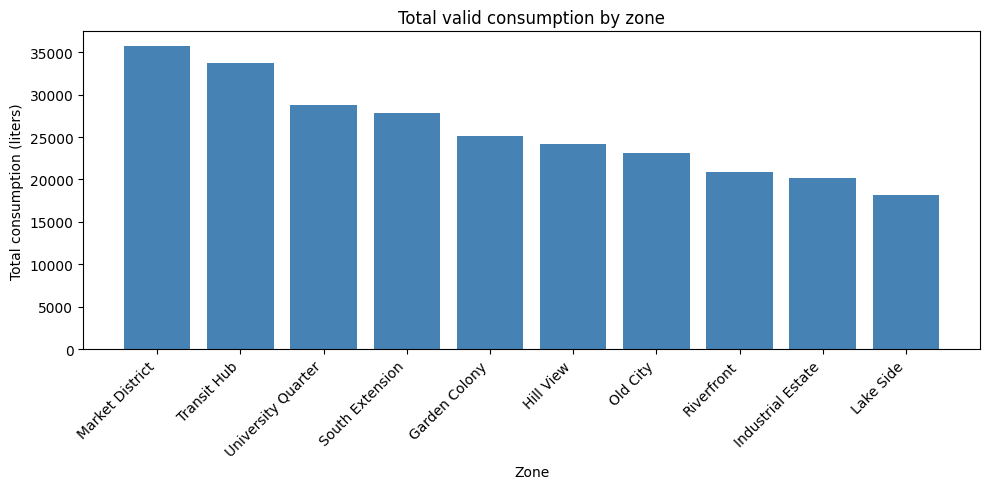

In [0]:
import matplotlib.pyplot as plt
zone_pdf = spark.sql("""
    SELECT z.zone_name, SUM(r.consumption_liters) AS total_consumption
    FROM water_readings_clean rJOIN water_zones z ON r.zone_id = z.zone_id GROUP BY z.zone_name ORDER BY total_consumption DESC
""").toPandas()
plt.figure(figsize=(10, 5))
plt.bar(zone_pdf["zone_name"], zone_pdf["total_consumption"], color="steelblue")
plt.title("Total valid consumption by zone")
plt.xlabel("Zone")
plt.ylabel("Total consumption (liters)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

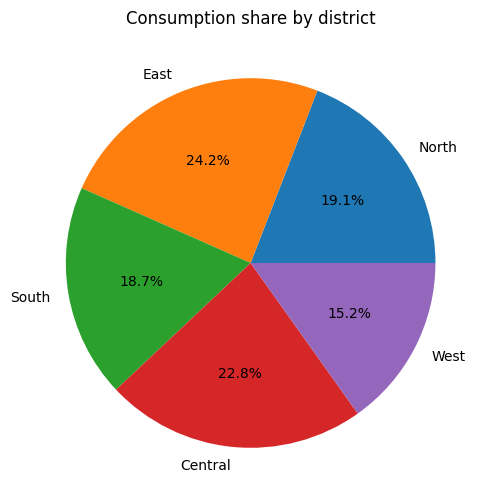

In [0]:
district_pdf = spark.sql("""
    SELECT z.district, SUM(r.consumption_liters) AS total_consumption FROM water_readings_clean r
    JOIN water_zones z ON r.zone_id = z.zone_id GROUP BY z.district
""").toPandas()
plt.figure(figsize=(6, 6))
plt.pie(district_pdf["total_consumption"], labels=district_pdf["district"], autopct="%1.1f%%")
plt.title("Consumption share by district")
plt.show()

54. Build a line chart showing daily total consumption and a scatter plot of pressure_bar versus flow_lpm for
valid readings.

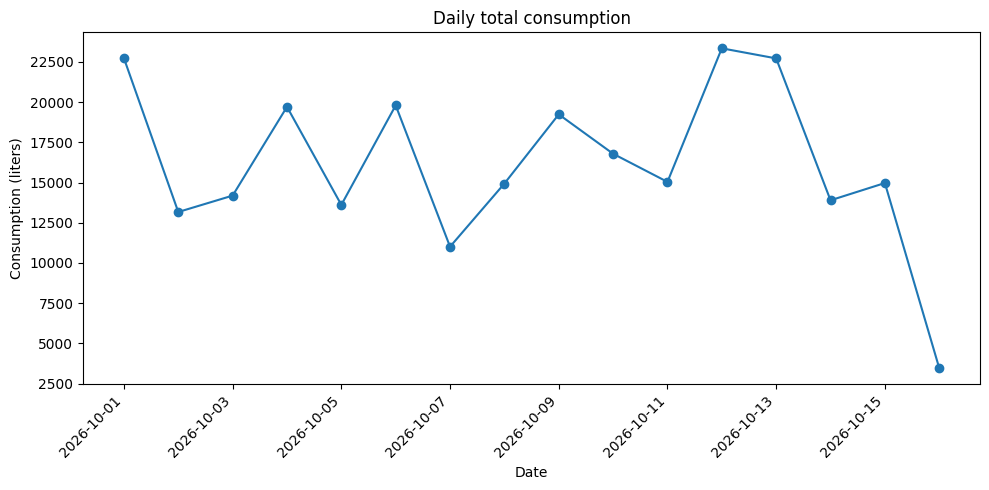

In [0]:
daily_pdf = spark.sql("""
    SELECT DATE(reading_time) AS reading_date, SUM(consumption_liters) AS daily_consumption FROM water_readings_clean
    GROUP BY DATE(reading_time) ORDER BY reading_date
""").toPandas()
plt.figure(figsize=(10, 5))
plt.plot(daily_pdf["reading_date"], daily_pdf["daily_consumption"], marker="o")
plt.title("Daily total consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (liters)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

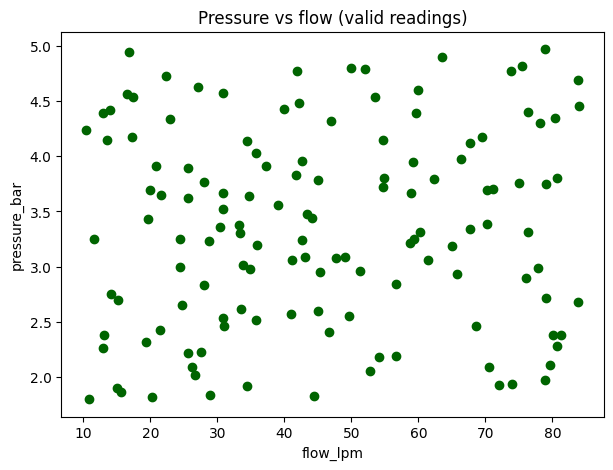

In [0]:
scatter_pdf = spark.sql("""
    SELECT flow_lpm, pressure_bar FROM water_readings_clean WHERE pressure_bar IS NOT NULL
""").toPandas()
plt.figure(figsize=(7, 5))
plt.scatter(scatter_pdf["flow_lpm"], scatter_pdf["pressure_bar"], color="darkgreen")
plt.title("Pressure vs flow (valid readings)")
plt.xlabel("flow_lpm")
plt.ylabel("pressure_bar")
plt.show()

55. Create a final dashboard or notebook report combining zone consumption, water-quality indicators and
service request counts; explain two operational findings.

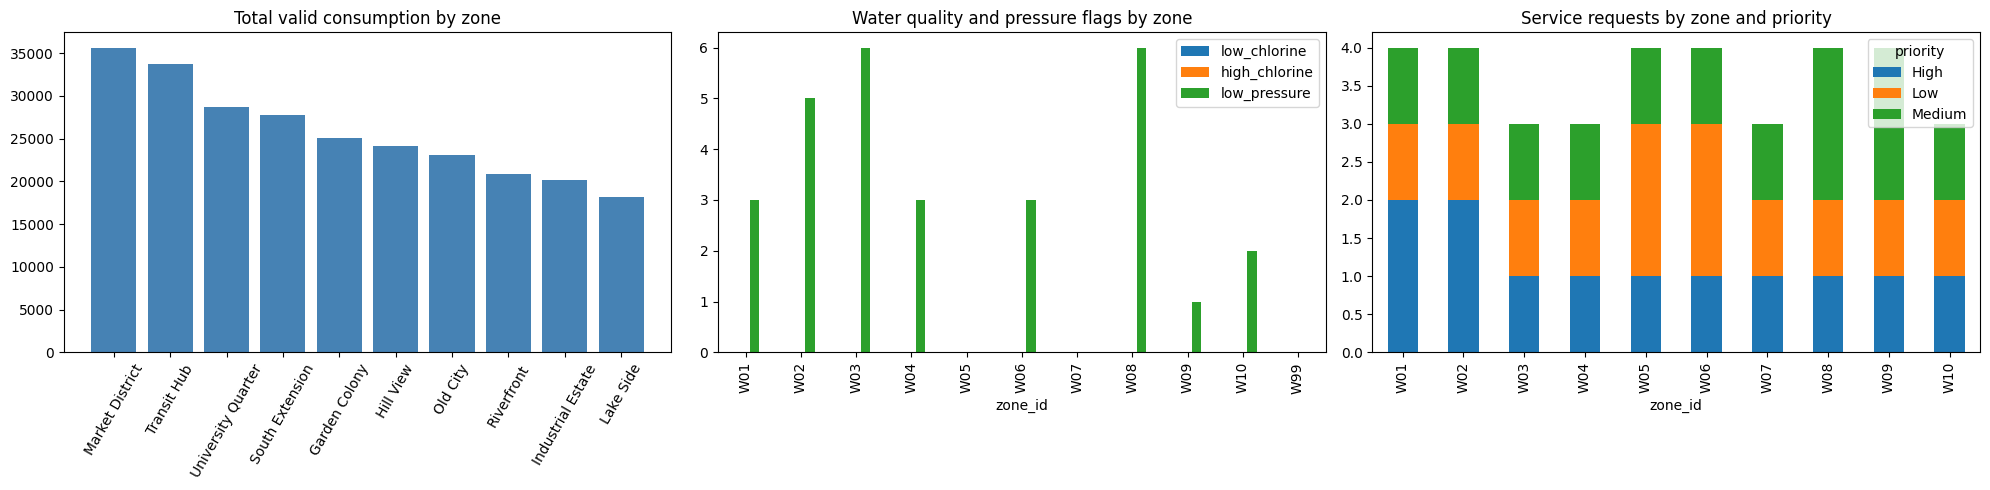

In [0]:
import matplotlib.pyplot as plt
zone_pdf = spark.sql("""
    SELECT z.zone_name, SUM(r.consumption_liters) AS total_consumption
    FROM water_readings_clean r
    JOIN water_zones z ON r.zone_id = z.zone_id
    GROUP BY z.zone_name
    ORDER BY total_consumption DESC
""").toPandas()
quality_pdf = spark.sql("""
    SELECT zone_id,
           SUM(CASE WHEN chlorine_mg_l < 0.2 THEN 1 ELSE 0 END) AS low_chlorine,
           SUM(CASE WHEN chlorine_mg_l > 4 THEN 1 ELSE 0 END) AS high_chlorine,
           SUM(CASE WHEN pressure_bar < 2.5 THEN 1 ELSE 0 END) AS low_pressure
    FROM water_readings_clean
    GROUP BY zone_id
    ORDER BY zone_id
""").toPandas().set_index("zone_id")
req_pdf = (spark.table("water_service_requests")
           .groupBy("zone_id", "priority").count()
           .toPandas()
           .pivot(index="zone_id", columns="priority", values="count")
           .fillna(0))
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].bar(zone_pdf["zone_name"], zone_pdf["total_consumption"], color="steelblue")
axes[0].set_title("Total valid consumption by zone")
axes[0].tick_params(axis="x", rotation=60)
quality_pdf.plot(kind="bar", ax=axes[1])
axes[1].set_title("Water quality and pressure flags by zone")
axes[1].set_xlabel("zone_id")
req_pdf.plot(kind="bar", stacked=True, ax=axes[2])
axes[2].set_title("Service requests by zone and priority")
axes[2].set_xlabel("zone_id")
plt.tight_layout()
plt.show()

In [0]:
display(zone_pdf)
display(quality_pdf.reset_index())
display(req_pdf.reset_index())

zone_name,total_consumption
Market District,35665
Transit Hub,33689
University Quarter,28717
South Extension,27808
Garden Colony,25104
Hill View,24120
Old City,23107
Riverfront,20894
Industrial Estate,20212
Lake Side,18120


zone_id,low_chlorine,high_chlorine,low_pressure
W01,0,0,3
W02,0,0,5
W03,0,0,6
W04,0,0,3
W05,0,0,0
W06,0,0,3
W07,0,0,0
W08,0,0,6
W09,0,0,1
W10,0,0,2


zone_id,High,Low,Medium
W01,2,1,1
W02,2,1,1
W03,1,1,1
W04,1,1,1
W05,1,2,1
W06,1,2,1
W07,1,1,1
W08,1,1,2
W09,1,1,2
W10,1,1,1


##Final capstone | Water Operations Analytics

In [0]:
%sql
CREATE OR REFRESH MATERIALIZED VIEW gold_district_summary
AS SELECT z.district,SUM(s.consumption_liters) AS total_consumption,ROUND(AVG(s.pressure_bar), 2) AS avg_pressure,COUNT(*) AS reading_count
FROM silver_readings s JOIN workspace.default.water_zones z ON s.zone_id = z.zone_id GROUP BY z.district;
CREATE OR REFRESH MATERIALIZED VIEW gold_quality_flags
AS SELECT reading_id, meter_id, zone_id, reading_time, pressure_bar, chlorine_mg_l,
CASE WHEN pressure_bar < 2.5 THEN true ELSE false END AS low_pressure_flag,
CASE WHEN chlorine_mg_l < 0.2 OR chlorine_mg_l > 4 THEN true ELSE false END AS chlorine_flag
FROM silver_readings WHERE pressure_bar < 2.5 OR chlorine_mg_l < 0.2 OR chlorine_mg_l > 4;

result
The operation was successfully executed.
